**Author:** Chelsea Volpano  
**Email:** cvolpano@contractor.usgs.gov | cvolpano@gmail.com  
**Date:** 2026-06-24  

Reads and compares PUV sensor file and TWL Viewer predictions 

In [32]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from pathlib import Path

In [2]:
def load_insitu(path, start, end):
    df = pd.read_csv(path, parse_dates=["time"])
    df = df.rename(columns={
        "time":        "datetime",
        "wh_4061":     "Hs",
        "wp_peak":     "Tp",
        "water_depth": "depth",
        "water_level": "water_level",
    })
    df = df.set_index("datetime")
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.loc[START:END]
    return df

def load_twlviewer(path, start, end):
    df = pd.read_csv(path, parse_dates=["dateTime"])
    df = df.set_index("dateTime")
    df = df.sort_index()
    df = df.loc[START:END]
    return df




In [3]:
#  ── Configuration ─────────────────────────────────────────────────────────────
OUT_DIR  = Path("wave_data")
PLOT_DIR = Path("wave_plots")
PLOT_DIR.mkdir(exist_ok=True)
INSITU_FILE = Path("sig1000_waves_ALL.csv")   
TWL_FILE = Path("TWL-Viewer-Data.csv")
START = "2024-10-01"
END = "2025-03-06"



In [4]:
if INSITU_FILE.exists():
    insitu = load_insitu(INSITU_FILE, START, END)
    print(f"In-situ loaded:     {len(insitu)} rows, {insitu.index.min()} → {insitu.index.max()}")
else:
    insitu = None
    print("In-situ file not found — skipping.")

if TWL_FILE.exists():
    twlviewer = load_twlviewer(TWL_FILE, START, END)
    print(f"TWL Viewer loaded:     {len(insitu)} rows, {insitu.index.min()} → {insitu.index.max()}")
else:
    twlviewer = None
    print("TWL Viewer file not found — skipping.")    

In-situ loaded:     2094 rows, 2024-12-09 18:00:00 → 2025-03-06 23:00:00
TWL Viewer loaded:     2094 rows, 2024-12-09 18:00:00 → 2025-03-06 23:00:00


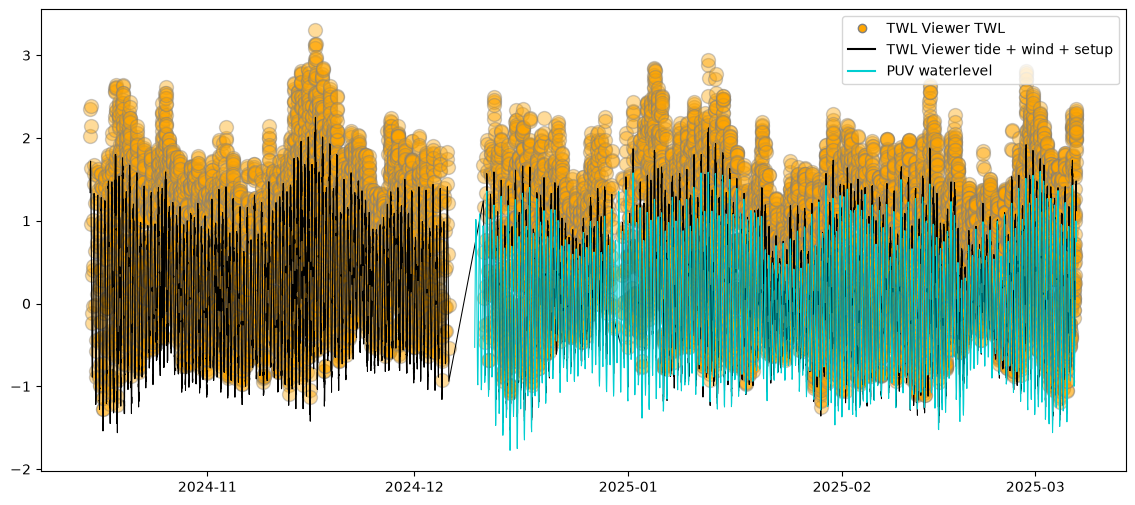

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(14, 6))
ax.plot(twlviewer['twl'], linestyle='none',marker='o',markersize = 10,linewidth=0.4,markeredgecolor='gray',markerfacecolor='orange',alpha=0.4)
ax.plot(twlviewer['tideWindSetup'], linewidth=0.75,color='black')
ax.plot(insitu['water_level'], linewidth=0.75,color = 'darkturquoise')

orange_marker = mlines.Line2D([],[],linestyle = 'none', marker = 'o',markerfacecolor = 'orange', markeredgecolor = 'gray', label = 'TWL Viewer TWL')
black_line = mlines.Line2D([],[], color = 'k', label = 'TWL Viewer tide + wind + setup')
blue_line = mlines.Line2D([],[], color = 'darkturquoise', label = 'PUV waterlevel')
ax.legend(handles = [orange_marker,black_line,blue_line])
plt.show()
